# 07 – How the surface changed: 26 October against 20 November 2026

The same pipeline (notebooks 02–05) was run on a second snapshot, taken on 20 November 2026 at 12:10
New York time, after a fall of the S&P 500 of about 8%. This notebook compares the two surfaces:
the level of volatility, the term structure, the skew and the cost of protection.

To rebuild the second surface, set `SNAPSHOT = "SPX_2026-11-20_1210"` in notebooks 02–05.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from functions import black_price, svi

DATA_DIR = "data"
SNAPSHOTS = {"26 Oct 2026": "SPX_2026-10-26_1030", "20 Nov 2026": "SPX_2026-11-20_1210"}
param_cols = ["a", "b", "rho", "m", "sig"]

surfaces = {}
for label, snap in SNAPSHOTS.items():
    s = pd.read_csv(os.path.join(DATA_DIR, snap + "_surface.csv"))
    surfaces[label] = s.sort_values("T").reset_index(drop=True)
    print(label, "- spot:", surfaces[label]["spot"].iloc[0], "- expiries:", len(s))

26 Oct 2026 - spot: 7673.61 - expiries: 47
20 Nov 2026 - spot: 7049.08 - expiries: 43


## 1. Volatility for any maturity

As in notebook 05, total variance is interpolated linearly in $T$ at fixed log-moneyness, and the
forward linearly in $\ln F$. The functions take the surface as an argument, so the same code works
for both dates.

In [2]:
def implied_vol(surface, k, T):
    T_list = surface["T"].values
    i = np.searchsorted(T_list, T) - 1
    i = min(max(i, 0), len(T_list) - 2)
    T1, T2 = T_list[i], T_list[i + 1]
    w1 = svi(k, *surface.loc[i, param_cols])
    w2 = svi(k, *surface.loc[i + 1, param_cols])
    w = w1 + (T - T1) / (T2 - T1) * (w2 - w1)
    return np.sqrt(w / T)

def forward(surface, T):
    return np.exp(np.interp(T, surface["T"].values, np.log(surface["F"].values)))

def rate(surface, T):
    return np.interp(T, surface["T"].values, surface["r"].values)

## 2. Key numbers

For each date: the spot, the at-the-money volatility at 1 month, 1 year and 2 years, the 1-year skew
(volatility at 90% of the forward minus at-the-money volatility) and the cost of 1-year puts in percent
of the spot. Strikes are set in percent of the spot of each date, as a hedge protects the value of the
portfolio on that day.

In [3]:
rows = []
for label, s in surfaces.items():
    S = s["spot"].iloc[0]
    F1, r1 = forward(s, 1.0), rate(s, 1.0)
    row = {"date": label, "spot": S,
           "ATM vol 1m (%)": implied_vol(s, 0, 1/12) * 100,
           "ATM vol 1y (%)": implied_vol(s, 0, 1.0) * 100,
           "ATM vol 2y (%)": implied_vol(s, 0, 2.0) * 100,
           "skew 1y (vol points)": (implied_vol(s, np.log(0.9), 1.0) - implied_vol(s, 0, 1.0)) * 100}
    for m in [0.9, 0.8]:
        K = m * S
        vol = implied_vol(s, np.log(K / F1), 1.0)
        row[f"put {int(m*100)}% 1y (% of spot)"] = black_price(F1, K, 1.0, r1, vol, "P") / S * 100
    rows.append(row)

table = pd.DataFrame(rows).set_index("date").round(2)
print(table.T)

date                    26 Oct 2026  20 Nov 2026
spot                        7673.61      7049.08
ATM vol 1m (%)                14.24        24.83
ATM vol 1y (%)                16.70        20.44
ATM vol 2y (%)                17.42        19.66
skew 1y (vol points)           3.30         3.46
put 90% 1y (% of spot)         2.90         4.10
put 80% 1y (% of spot)         1.69         2.51


## 3. Term structure and smile

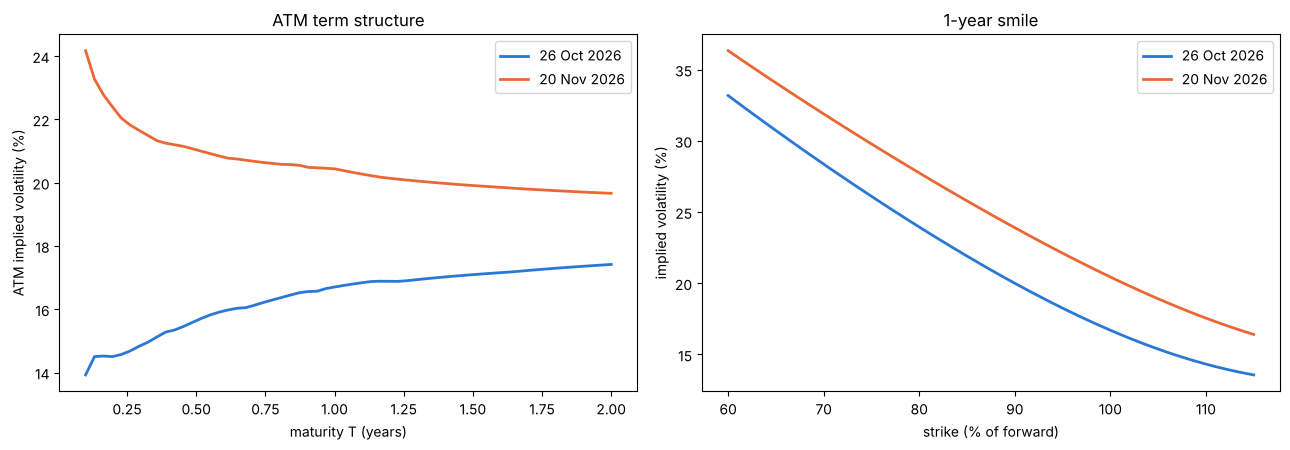

In [4]:
colors = {"26 Oct 2026": "#2a78d6", "20 Nov 2026": "#eb6834"}
T_grid = np.linspace(0.1, 2.0, 60)
mny = np.linspace(0.6, 1.15, 120)                  # strike / forward

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
for label, s in surfaces.items():
    atm = [implied_vol(s, 0, T) * 100 for T in T_grid]
    ax1.plot(T_grid, atm, color=colors[label], lw=2, label=label)
    ax2.plot(mny * 100, implied_vol(s, np.log(mny), 1.0) * 100, color=colors[label], lw=2, label=label)

ax1.set_xlabel("maturity T (years)")
ax1.set_ylabel("ATM implied volatility (%)")
ax1.set_title("ATM term structure")
ax1.legend()
ax2.set_xlabel("strike (% of forward)")
ax2.set_ylabel("implied volatility (%)")
ax2.set_title("1-year smile")
ax2.legend()
plt.tight_layout()
plt.show()

## 4. The two surfaces side by side

Both surfaces are drawn with the same axes and the same colour scale, so that the change in level
can be read directly from the colours.

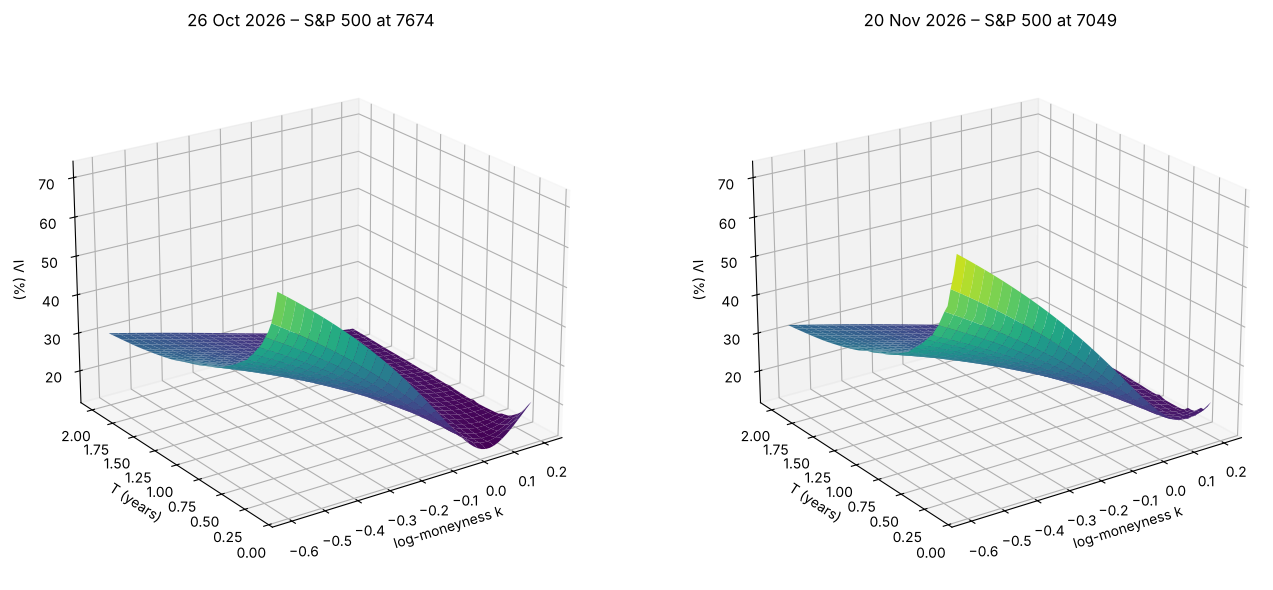

In [5]:
k_grid = np.linspace(-0.6, 0.2, 60)
T_grid = np.linspace(0.1, 2.0, 60)
K_mesh, T_mesh = np.meshgrid(k_grid, T_grid)

Z = {}
for label, s in surfaces.items():
    Z[label] = np.array([implied_vol(s, k_grid, T) * 100 for T in T_grid])
z_min = min(z.min() for z in Z.values())
z_max = max(z.max() for z in Z.values())

fig = plt.figure(figsize=(14, 6))
for n, (label, s) in enumerate(surfaces.items()):
    ax = fig.add_subplot(1, 2, n + 1, projection="3d")
    ax.plot_surface(K_mesh, T_mesh, Z[label], cmap="viridis", vmin=z_min, vmax=z_max, edgecolor="none")
    ax.set_zlim(z_min, z_max)
    ax.set_xlabel("log-moneyness k")
    ax.set_ylabel("T (years)")
    ax.set_zlabel("IV (%)")
    ax.set_title(f"{label} – S&P 500 at {s['spot'].iloc[0]:.0f}")
    ax.view_init(elev=22, azim=-125)
plt.tight_layout()
plt.show()

## 5. Result

Between the two dates the S&P 500 fell by about 8%, and implied volatility rose at all maturities,
but much more at the short end. The 1-month at-the-money volatility went from 14.2% to 24.8%,
while the 1-year one went from 16.7% to 20.4%. The term structure, which was upward sloping in
October, is now inverted, a typical sign of market stress.

The 1-year skew changed very little (from 3.3 to 3.5 volatility points): the whole smile moved up,
while its shape stayed almost the same. As a result, protection became much more expensive. The
1-year 90% put went from 2.9% to 4.1% of the spot, about 40% more, and the 80% put from 1.7% to 2.5%.

The second snapshot was taken in a fast-moving market, so some quotes were not updated at the same
time. The local filter of notebook 04 does not remove clusters of stale quotes, which increases the
largest fit errors. In the hedging region, however, the surface is still free of calendar arbitrage,
and 95% of the volatility errors are below 0.32 points.